# Тема 1. Графы знаний, семантические технологии
## Семинар 1. Семантические сети и RDF/Turtle

In [1]:
from IPython.display import display, HTML, SVG
from pathlib import Path
import html as _html

def show_table(headers, rows):
    head = "".join(f"<th>{_html.escape(str(h))}</th>" for h in headers)
    body = []
    for row in rows:
        body.append(
            "<tr>" +
            "".join(f"<td>{_html.escape(str(v))}</td>" for v in row) +
            "</tr>"
        )
    display(HTML(
        '<table style="border-collapse:collapse; width:100%; margin:8px 0 18px 0;">'
        '<thead><tr>' + head + '</tr></thead>'
        '<tbody>' + "".join(body) + '</tbody></table>'
        '<style>'
        'table th, table td {border:1px solid #bbb; padding:7px 9px; vertical-align:top;}'
        'table th {font-weight:600; background:#f5f5f5;}'
        '</style>'
    ))

def short_iri(value, base="http://example.org/semtech/"):
    return "ex:" + value[len(base):] if value.startswith(base) else value

#print("Среда готова. Внешние Python-пакеты не требуются.")

## 1. От данных к графу знаний

Отдельное значение не обязательно несёт смысл, понятный программе. Число `42` может означать возраст, номер аудитории, количество студентов или внутренний идентификатор. Смысл появляется только после того, как значение связывается с объектом и контекстом.

Условный переход от исходных данных к использованию знания:

$$
D \rightarrow I \rightarrow K \rightarrow A,
$$

где $D$ - данные, $I$ - интерпретированная информация, $K$ - формализованное знание, $A$ - действие или решение.

Запись `Анна, Семантические технологии` неоднозначна. Утверждение `Анна изучает курс Семантические технологии` уже задаёт две сущности и тип связи. Если дополнительно известны типы объектов, источник факта и временной контекст, утверждение можно объединять с другими данными, проверять и использовать в алгоритмах.

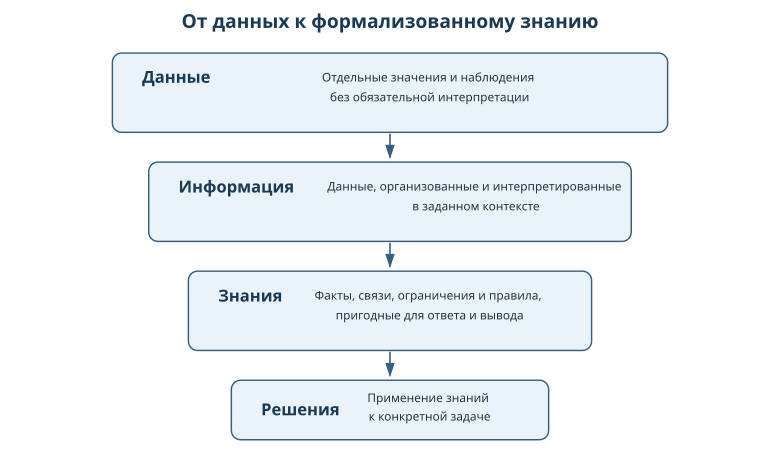

In [2]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="780" height="463" viewBox="0 0 1180 700">
  <rect width="1180" height="700" fill="white"/>
  <defs>
    <marker id="arrow" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#355f7c"/>
    </marker>
    <style>
      .box { fill:#eaf3fa; stroke:#355f7c; stroke-width:2.2; }
      .title { font:700 25px sans-serif; fill:#183a54; }
      .body { font:18px sans-serif; fill:#25333d; text-anchor:middle; }
      .head { font:700 29px sans-serif; fill:#183a54; text-anchor:middle; }
      .arrow { stroke:#355f7c; stroke-width:2.4; marker-end:url(#arrow); }
    </style>
  </defs>

  <text x="590" y="42" class="head">От данных к формализованному знанию</text>

  <rect x="170" y="80" width="840" height="120" rx="14" class="box"/>
  <text x="215" y="125" class="title">Данные</text>
  <text x="650" y="123" class="body">
    <tspan x="650" dy="0">Отдельные значения и наблюдения</tspan>
    <tspan x="650" dy="30">без обязательной интерпретации</tspan>
  </text>

  <line x1="590" y1="202" x2="590" y2="238" class="arrow"/>

  <rect x="225" y="245" width="730" height="120" rx="14" class="box"/>
  <text x="270" y="291" class="title">Информация</text>
  <text x="720" y="288" class="body">
    <tspan x="720" dy="0">Данные, организованные и интерпретированные</tspan>
    <tspan x="720" dy="30">в заданном контексте</tspan>
  </text>

  <line x1="590" y1="367" x2="590" y2="403" class="arrow"/>

  <rect x="285" y="410" width="610" height="120" rx="14" class="box"/>
  <text x="330" y="456" class="title">Знания</text>
  <text x="650" y="453" class="body">
    <tspan x="650" dy="0">Факты, связи, ограничения и правила,</tspan>
    <tspan x="650" dy="30">пригодные для ответа и вывода</tspan>
  </text>

  <line x1="590" y1="532" x2="590" y2="568" class="arrow"/>

  <rect x="350" y="575" width="480" height="90" rx="14" class="box"/>
  <text x="395" y="628" class="title">Решения</text>
  <text x="650" y="608" class="body">
    <tspan x="650" dy="0">Применение знаний</tspan>
    <tspan x="650" dy="28">к конкретной задаче</tspan>
  </text>
</svg>
"""
display(SVG(svg))

**Основные модели представления.** Реляционная модель удобна при стабильной схеме и транзакционной обработке. Документная модель хорошо передаёт составной объект. Графовая модель удобна, когда центральную роль играют связи. RDF-граф добавляет глобальные идентификаторы и единообразное представление фактов.

In [3]:
show_table(
    ["Модель", "Основная единица", "Связи", "Схема", "Типичный язык запросов"],
    [
        ["Реляционная", "строка", "внешние ключи", "обычно строгая", "SQL"],
        ["Документная", "документ", "вложенность и ссылки", "гибкая", "зависит от системы"],
        ["Граф свойств", "вершина / ребро", "явные рёбра", "гибкая", "Cypher, Gremlin и др."],
        ["RDF-граф", "тройка", "предикаты", "открытая и расширяемая", "SPARQL"],
    ],
)

Модель,Основная единица,Связи,Схема,Типичный язык запросов
Реляционная,строка,внешние ключи,обычно строгая,SQL
Документная,документ,вложенность и ссылки,гибкая,зависит от системы
Граф свойств,вершина / ребро,явные рёбра,гибкая,"Cypher, Gremlin и др."
RDF-граф,тройка,предикаты,открытая и расширяемая,SPARQL


Для ориентированного графа используется запись:

$$
G=(V,E),
$$

где $V$ — множество вершин, $E$ — множество рёбер.

Семантическое ребро представим как:

$$
e=(u,r,v),
$$

где $u$ — исходная сущность, $r$ — тип отношения, $v$ — целевая сущность.

Например:

$$
(\mathrm{Анна},\ \mathrm{изучает},\ \mathrm{Курс\ СТ}).
$$

В графе свойств дополнительно могут использоваться метки вершин, метки рёбер и наборы свойств:

$$
G_P=(V,E,\lambda_V,\lambda_E,\pi),
$$

где $\lambda_V$ и $\lambda_E$ задают метки вершин и рёбер, а $\pi$ — дополнительные свойства элементов графа.

## 2. Граф знаний, семантическая сеть и онтология

**Граф знаний** представляет собой граф фактов о сущностях предметной области, связанный со схемой понятий и отношений, а также, при необходимости, с метаданными о происхождении и качестве утверждений.

Модель графа знаний:

$$
KG=(G,S,P),
$$

где $G$ - граф фактов, $S$ - схема понятий и отношений, $P$ - метаданные происхождения, времени и доверия.

**Сущность** - различимый объект предметной области с устойчивой идентичностью. Имя не является самой сущностью: разные объекты могут иметь одинаковые имена, а одна сущность может иметь несколько вариантов имени.

**Класс** объединяет сущности общего типа. `Студент`, `Преподаватель`, `Учебный курс` - классы; Анна Смирнова и конкретный курс - экземпляры. Для отношения подкласса действует правило:

$$
x \in A \land A \subseteq B \Rightarrow x \in B.
$$

**Отношение** связывает две сущности и должно иметь устойчивый смысл и направление. Например, `преподаватель → ведёт → курс`.

**Атрибут** связывает сущность со значением: названием, числом, датой, кодом. В RDF это также тройка, но объектом является литерал.

**Происхождение и время** особенно важны для изменяющихся фактов. Утверждение `Петрова ведёт Курс СТ` может относиться только к конкретному семестру.

**Семантическая сеть** служит промежуточным представлением между естественным языком и формальным RDF-графом.

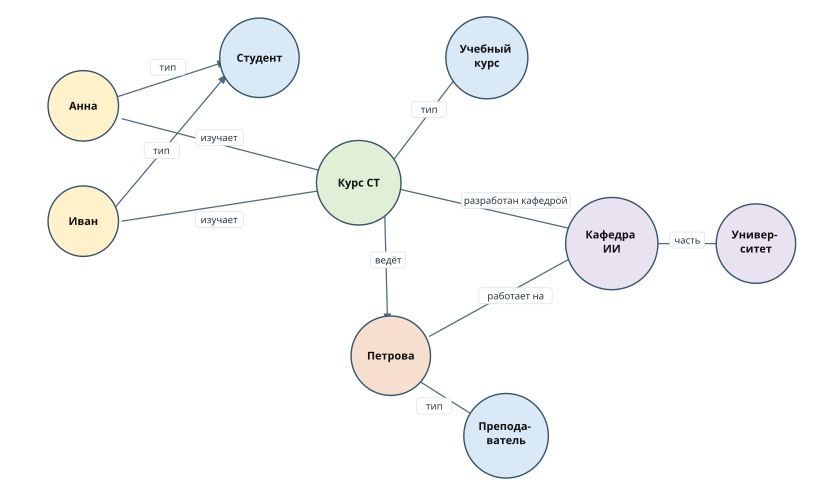

In [4]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="820" height="500" viewBox="0 0 1280 780">
  <rect width="1280" height="780" fill="white"/>
  <defs>
    <marker id="arr" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#506b7f"/>
    </marker>
    <style>
      .edge { stroke:#506b7f; stroke-width:2; marker-end:url(#arr); }
      .edgeLabel { font:15px sans-serif; fill:#263742; text-anchor:middle; }
      .labBg { fill:white; stroke:#d7dfe5; stroke-width:1; rx:5; }
      .node { stroke:#35556d; stroke-width:2.2; }
      .inst { fill:#fff1c9; }
      .class { fill:#d9e9f6; }
      .course { fill:#e1efd7; }
      .org { fill:#e9e2f1; }
      .teacher { fill:#f7dfd0; }
      .nodeText { font:700 17px sans-serif; fill:#111; text-anchor:middle; }
      .title { font:700 27px sans-serif; fill:#111; text-anchor:middle; }
    </style>
  </defs>

  

  <!-- edges -->
  <line x1="170" y1="155" x2="355" y2="95" class="edge"/>
  <line x1="170" y1="335" x2="355" y2="115" class="edge"/>
  <line x1="190" y1="185" x2="515" y2="270" class="edge"/>
  <line x1="190" y1="345" x2="515" y2="295" class="edge"/>
  <line x1="610" y1="255" x2="720" y2="110" class="edge"/>
  <line x1="600" y1="310" x2="605" y2="505" class="edge"/>
  <line x1="610" y1="292" x2="905" y2="360" class="edge"/>
  <line x1="670" y1="525" x2="905" y2="395" class="edge"/>
  <line x1="615" y1="570" x2="750" y2="655" class="edge"/>
  <line x1="1010" y1="380" x2="1135" y2="380" class="edge"/>

  <!-- label backgrounds + labels -->
  <rect x="235" y="92" width="55" height="25" class="labBg"/><text x="262" y="110" class="edgeLabel">тип</text>
  <rect x="225" y="222" width="55" height="25" class="labBg"/><text x="252" y="240" class="edgeLabel">тип</text>

  <rect x="305" y="202" width="75" height="25" class="labBg"/><text x="342" y="220" class="edgeLabel">изучает</text>
  <rect x="305" y="330" width="75" height="25" class="labBg"/><text x="342" y="348" class="edgeLabel">изучает</text>

  <rect x="642" y="158" width="55" height="25" class="labBg"/><text x="670" y="176" class="edgeLabel">тип</text>
  <rect x="578" y="393" width="55" height="25" class="labBg"/><text x="606" y="411" class="edgeLabel">ведёт</text>

  <rect x="720" y="300" width="170" height="25" class="labBg"/><text x="805" y="318" class="edgeLabel">разработан кафедрой</text>
  <rect x="747" y="449" width="115" height="25" class="labBg"/><text x="805" y="467" class="edgeLabel">работает на</text>

  <rect x="650" y="621" width="55" height="25" class="labBg"/><text x="678" y="639" class="edgeLabel">тип</text>
  <rect x="1045" y="362" width="55" height="25" class="labBg"/><text x="1073" y="380" class="edgeLabel">часть</text>

  <!-- nodes -->
  <circle cx="130" cy="165" r="55" class="node inst"/>
  <text x="130" y="171" class="nodeText">Анна</text>

  <circle cx="130" cy="345" r="55" class="node inst"/>
  <text x="130" y="351" class="nodeText">Иван</text>

  <circle cx="405" cy="90" r="62" class="node class"/>
  <text x="405" y="96" class="nodeText">Студент</text>

  <circle cx="560" cy="285" r="66" class="node course"/>
  <text x="560" y="291" class="nodeText">Курс СТ</text>

  <circle cx="760" cy="90" r="64" class="node class"/>
  <text x="760" y="82" class="nodeText">
    <tspan x="760" dy="0">Учебный</tspan>
    <tspan x="760" dy="22">курс</tspan>
  </text>

  <circle cx="610" cy="555" r="62" class="node teacher"/>
  <text x="610" y="561" class="nodeText">Петрова</text>

  <circle cx="790" cy="680" r="66" class="node class"/>
  <text x="790" y="671" class="nodeText">
    <tspan x="790" dy="0">Препода-</tspan>
    <tspan x="790" dy="22">ватель</tspan>
  </text>

  <circle cx="955" cy="380" r="72" class="node org"/>
  <text x="955" y="372" class="nodeText">
    <tspan x="955" dy="0">Кафедра</tspan>
    <tspan x="955" dy="22">ИИ</tspan>
  </text>

  <circle cx="1180" cy="380" r="62" class="node org"/>
  <text x="1180" y="372" class="nodeText">
    <tspan x="1180" dy="0">Универ-</tspan>
    <tspan x="1180" dy="22">ситет</tspan>
  </text>
</svg>
"""
display(SVG(svg))

In [5]:
show_table(
    ["Компонент", "Пример", "Смысл"],
    [
        ["Сущность", "Анна Смирнова", "конкретный различимый объект"],
        ["Класс", "Студент", "тип объектов"],
        ["Объектное отношение", "изучает курс", "ресурс → ресурс"],
        ["Атрибут", "зачётные единицы", "ресурс → литерал"],
        ["Происхождение", "учебный план", "источник утверждения"],
        ["Временной контекст", "осень 2026", "период действия факта"],
    ],
)

Компонент,Пример,Смысл
Сущность,Анна Смирнова,конкретный различимый объект
Класс,Студент,тип объектов
Объектное отношение,изучает курс,ресурс → ресурс
Атрибут,зачётные единицы,ресурс → литерал
Происхождение,учебный план,источник утверждения
Временной контекст,осень 2026,период действия факта


**Онтология как схема графа.** Она формально описывает классы, свойства и ограничения, необходимые для интерпретации фактов.

В логических базах знаний часто различают:

- **TBox**, терминологическую часть: определения классов и свойств;
- **ABox**, фактологическую часть: утверждения о конкретных экземплярах.

Тогда базу знаний можно представить как

$$
KB=T\cup A,
$$

где $T$ содержит схему, а $A$ содержит факты о конкретных экземплярах.

Например, `Student` - класс, `Course` - класс и `enrolledIn` - отношение `Student → Course` относятся к TBox. Факты `Anna rdf:type Student` и `Anna enrolledIn SemTech` относятся к ABox.

**Использование в ИИ.** Графы знаний применяются при распознавании и связывании сущностей, извлечении отношений, вопросно-ответном поиске, рекомендациях и Retrieval-Augmented Generation. Путь по графу может использоваться как объяснение ответа.

In [6]:
# Исполняемый пример двухшагового ответа без сторонних библиотек.
facts = [
    ("Анна", "изучает", "Курс СТ"),
    ("Петрова", "ведёт", "Курс СТ"),
]

anna_courses = [o for s, p, o in facts if s == "Анна" and p == "изучает"]
teachers = [s for s, p, o in facts if p == "ведёт" and o in anna_courses]

show_table(
    ["Шаг", "Результат"],
    [
        ["Курс, который изучает Анна", ", ".join(anna_courses)],
        ["Преподаватель найденного курса", ", ".join(teachers)],
    ]
)

Шаг,Результат
"Курс, который изучает Анна",Курс СТ
Преподаватель найденного курса,Петрова


## 3. Алгоритм построения семантической сети

**Вход** текстовый фрагмент и список задач, которые должна поддерживать модель.
**Выход** набор узлов, отношений, атрибутов и ограничений.

Переход от естественного языка к графу выполняется итерационно за счет:

1. определения границ предметной области и вопросов, на которые должна отвечать модель;
2. выделения именных групп — кандидатов в сущности;
3. нормализации названия и устранения дублей;
4. разделения классов и конкретных экземпляров;
5. выделения глагольных и предложных конструкций — кандидатов в отношения;
6. отделения отношений между сущностями от атрибутов-значений;
7. установления направления каждого отношения;
8. назначения устойчивых идентификаторов;
9. записи фактов в форме троек;
10. проверки модели по исходным вопросам и, при необходимости, повторении цикла.

Ключевой принцип: модель строится как структура, способная поддерживать конкретные вопросы и операции.

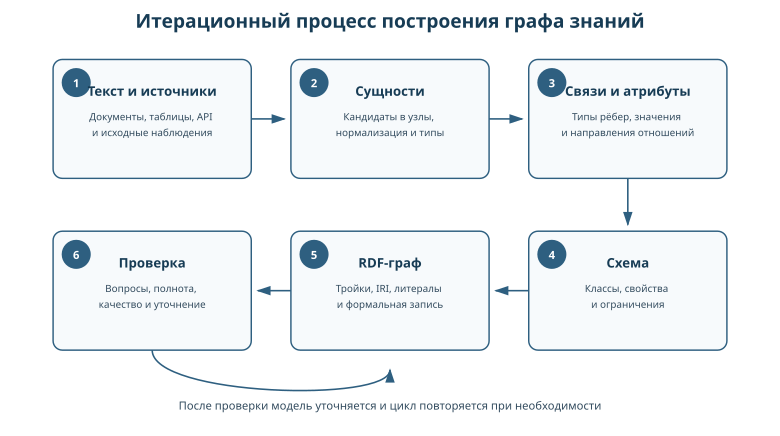

In [7]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="780" height="436" viewBox="0 0 1180 660">
  <rect width="1180" height="660" fill="white"/>
  <defs>
    <marker id="arr" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#2e5f80"/>
    </marker>
    <style>
      .box { fill:#f7fafc; stroke:#2e5f80; stroke-width:2.2; }
      .num { fill:#2e5f80; }
      .numText { font:700 17px sans-serif; fill:white; text-anchor:middle; dominant-baseline:middle; }
      .title { font:700 20px sans-serif; fill:#173c55; text-anchor:middle; }
      .body { font:15px sans-serif; fill:#314a5d; text-anchor:middle; }
      .arrow { stroke:#2e5f80; stroke-width:2.4; marker-end:url(#arr); fill:none; }
      .head { font:700 29px sans-serif; fill:#173c55; text-anchor:middle; }
      .note { font:17px sans-serif; fill:#314a5d; text-anchor:middle; }
    </style>
  </defs>

  <text x="590" y="42" class="head">Итерационный процесс построения графа знаний</text>

  <!-- row 1 -->
  <rect x="80" y="90" width="300" height="180" rx="14" class="box"/>
  <circle cx="115" cy="125" r="22" class="num"/><text x="115" y="126" class="numText">1</text>
  <text x="230" y="145" class="title">Текст и источники</text>
  <text x="230" y="182" class="body">
    <tspan x="230" dy="0">Документы, таблицы, API</tspan>
    <tspan x="230" dy="24">и исходные наблюдения</tspan>
  </text>

  <rect x="440" y="90" width="300" height="180" rx="14" class="box"/>
  <circle cx="475" cy="125" r="22" class="num"/><text x="475" y="126" class="numText">2</text>
  <text x="590" y="145" class="title">Сущности</text>
  <text x="590" y="182" class="body">
    <tspan x="590" dy="0">Кандидаты в узлы,</tspan>
    <tspan x="590" dy="24">нормализация и типы</tspan>
  </text>

  <rect x="800" y="90" width="300" height="180" rx="14" class="box"/>
  <circle cx="835" cy="125" r="22" class="num"/><text x="835" y="126" class="numText">3</text>
  <text x="950" y="145" class="title">Связи и атрибуты</text>
  <text x="950" y="182" class="body">
    <tspan x="950" dy="0">Типы рёбер, значения</tspan>
    <tspan x="950" dy="24">и направления отношений</tspan>
  </text>

  <!-- row 2 -->
  <rect x="800" y="350" width="300" height="180" rx="14" class="box"/>
  <circle cx="835" cy="385" r="22" class="num"/><text x="835" y="386" class="numText">4</text>
  <text x="950" y="405" class="title">Схема</text>
  <text x="950" y="442" class="body">
    <tspan x="950" dy="0">Классы, свойства</tspan>
    <tspan x="950" dy="24">и ограничения</tspan>
  </text>

  <rect x="440" y="350" width="300" height="180" rx="14" class="box"/>
  <circle cx="475" cy="385" r="22" class="num"/><text x="475" y="386" class="numText">5</text>
  <text x="590" y="405" class="title">RDF-граф</text>
  <text x="590" y="442" class="body">
    <tspan x="590" dy="0">Тройки, IRI, литералы</tspan>
    <tspan x="590" dy="24">и формальная запись</tspan>
  </text>

  <rect x="80" y="350" width="300" height="180" rx="14" class="box"/>
  <circle cx="115" cy="385" r="22" class="num"/><text x="115" y="386" class="numText">6</text>
  <text x="230" y="405" class="title">Проверка</text>
  <text x="230" y="442" class="body">
    <tspan x="230" dy="0">Вопросы, полнота,</tspan>
    <tspan x="230" dy="24">качество и уточнение</tspan>
  </text>

  <!-- arrows -->
  <line x1="380" y1="180" x2="430" y2="180" class="arrow"/>
  <line x1="740" y1="180" x2="790" y2="180" class="arrow"/>
  <path d="M950 270 L950 340" class="arrow"/>
  <line x1="800" y1="440" x2="750" y2="440" class="arrow"/>
  <line x1="440" y1="440" x2="390" y2="440" class="arrow"/>

  <path d="M230 530 C230 600, 590 610, 590 560" class="arrow"/>
  <text x="590" y="620" class="note">
    После проверки модель уточняется и цикл повторяется при необходимости
  </text>
</svg>
"""
display(SVG(svg))

### 3.1. Метрики и критерии качества графа

Количество узлов и рёбер само по себе не гарантирует полезность графа. Важно оценивать, насколько модель позволяет отвечать на поставленные вопросы и насколько однозначно представлены факты.

**Полнота.** Полнота показывает, достаточно ли фактов для ответа на контрольные вопросы. Если $F_{req}$ - набор фактов, необходимых для решения поставленных задач, а $F_{KG}$ - факты, представленные в графе, ориентировочную полноту можно оценить как

$$
C=\frac{|F_{req}\cap F_{KG}|}{|F_{req}|}.
$$

**Непротиворечивость.** Граф не должен содержать несовместимых утверждений без явного контекста. Например, один и тот же курс не должен одновременно иметь 4 и 6 зачётных единиц для одного и того же плана и периода.

**Однозначность предикатов.** Каждый предикат должен иметь стабильный смысл и единое направление. Один предикат не следует использовать для отношений, которые приложение должно трактовать по-разному.

**Связность.** Изолированные узлы могут указывать на пропущенные отношения. При этом максимальная связность не является целью: связь добавляют только тогда, когда она выражает содержательный факт.

Для ориентировочной оценки плотности простого ориентированного графа без петель можно использовать

$$
\delta=\frac{|E|}{|V|(|V|-1)}.
$$

Для графа знаний плотность обычно невелика, поскольку потенциальных пар сущностей значительно больше, чем осмысленных отношений.

**Происхождение.** Для значимых фактов желательно фиксировать источник и, если нужно, дату действия. Это помогает объяснять ответы системы и разрешать конфликты между источниками.

## 4. Пример: университетская предметная область

**Исходное описание.**

> В университете существует кафедра искусственного интеллекта. Доцент Елена Петрова работает на кафедре и ведёт курс Семантические технологии. Курс имеет код ST-101 и объём 4 зачётные единицы. Студенты Анна Смирнова и Иван Орлов изучают этот курс. Анна и Иван входят в группу ИСТ-41. Группа относится к образовательной программе Прикладная информатика.

**Вопросы к модели.**

1. Какие студенты изучают курс ST-101?
2. Кто ведёт этот курс?
3. На какой кафедре работает преподаватель?
4. Каков объём курса в зачётных единицах?
5. К какой образовательной программе относится группа студентов?

**Границы модели.** Включаем университет, кафедру, преподавателя, студентов, курс, группу и образовательную программу. Расписание, оценки, зарплата и аудитории в пример не включаются.

**Идентификаторы и пространство имён.** В RDF сущности, классы и свойства идентифицируются с помощью IRI. IRI - это глобальный идентификатор ресурса; он позволяет однозначно ссылаться на один и тот же ресурс в разных частях графа и в разных наборах данных. Полные IRI строятся в одном пространстве имён, например:

```text
http://example.org/semtech/
```

Полный идентификатор класса `Student` имеет вид:

```text
http://example.org/semtech/Student
```

Чтобы не повторять длинный адрес в каждой тройке, вводится префикс:

```turtle
@prefix ex: <http://example.org/semtech/> .
```

Префикс **ex** обозначает учебное пространство имён http://example.org/semtech/. В реальном проекте вместо демонстрационного адреса используется домен организации или иная контролируемая система идентификаторов.

После этого запись `ex:Student` означает тот же IRI `http://example.org/semtech/Student`. Аналогично `ex:Anna`, `ex:SemTech`, `ex:teaches` и другие записи являются сокращённой формой полных IRI. Префикс `ex:` не является частью имени сущности: это только удобное сокращение пространства имён.

**Выделение сущностей, классов и значений.** После введения пространства имён можно назначить IRI элементам модели. `ex:University` используется как класс, а конкретный университет получает отдельный IRI `ex:ExampleUniversity`. Код курса `ST-101` и число зачётных единиц не требуют собственной идентичности и остаются литералами.

In [8]:
show_table(
    ["Фрагмент", "IRI", "Категория", "Тип"],
    [
        ["Учебный университет", "ex:ExampleUniversity", "сущность", "ex:University"],
        ["Кафедра искусственного интеллекта", "ex:AIDepartment", "сущность", "ex:Department"],
        ["Елена Петрова", "ex:Petrova", "сущность", "ex:Teacher"],
        ["Семантические технологии", "ex:SemTech", "сущность", "ex:Course"],
        ["Анна Смирнова", "ex:Anna", "сущность", "ex:Student"],
        ["Иван Орлов", "ex:Ivan", "сущность", "ex:Student"],
        ["ИСТ-41", "ex:GroupIST41", "сущность", "ex:StudentGroup"],
        ["Прикладная информатика", "ex:AppliedInformatics", "сущность", "ex:EducationProgram"],
        ["ST-101", "—", "литерал", "xsd:string"],
        ["4", "—", "литерал", "xsd:integer"],
    ],
)

Фрагмент,IRI,Категория,Тип
Учебный университет,ex:ExampleUniversity,сущность,ex:University
Кафедра искусственного интеллекта,ex:AIDepartment,сущность,ex:Department
Елена Петрова,ex:Petrova,сущность,ex:Teacher
Семантические технологии,ex:SemTech,сущность,ex:Course
Анна Смирнова,ex:Anna,сущность,ex:Student
Иван Орлов,ex:Ivan,сущность,ex:Student
ИСТ-41,ex:GroupIST41,сущность,ex:StudentGroup
Прикладная информатика,ex:AppliedInformatics,сущность,ex:EducationProgram
ST-101,—,литерал,xsd:string
4,—,литерал,xsd:integer


**Отношения, атрибуты и направление.** Предикат выбирается так, чтобы он одинаково читался для всех фактов. `ex:teaches` всегда направляется от преподавателя к курсу, `ex:enrolledIn` — от студента к курсу.

In [9]:
show_table(
    ["Предикат", "Направление / диапазон", "Смысл"],
    [
        ["ex:partOf", "кафедра → университет", "кафедра является частью университета"],
        ["ex:worksAt", "преподаватель → кафедра", "преподаватель работает на кафедре"],
        ["ex:teaches", "преподаватель → курс", "преподаватель ведёт курс"],
        ["ex:enrolledIn", "студент → курс", "студент изучает курс"],
        ["ex:memberOf", "студент → группа", "студент входит в группу"],
        ["ex:belongsToProgram", "группа → программа", "группа относится к программе"],
        ["ex:courseCode", "курс → строка", "код курса"],
        ["ex:credits", "курс → целое число", "объём курса"],
        ["ex:fullName", "человек → строка", "полное имя"],
    ],
)

Предикат,Направление / диапазон,Смысл
ex:partOf,кафедра → университет,кафедра является частью университета
ex:worksAt,преподаватель → кафедра,преподаватель работает на кафедре
ex:teaches,преподаватель → курс,преподаватель ведёт курс
ex:enrolledIn,студент → курс,студент изучает курс
ex:memberOf,студент → группа,студент входит в группу
ex:belongsToProgram,группа → программа,группа относится к программе
ex:courseCode,курс → строка,код курса
ex:credits,курс → целое число,объём курса
ex:fullName,человек → строка,полное имя


**Запись фактов в виде RDF-троек.**

После того как сущностям, классам и свойствам назначены IRI, предметные факты можно записывать как тройки вида

$$
(\text{субъект},\ \text{предикат},\ \text{объект}).
$$

Например:

```text
ex:Anna  ex:enrolledIn  ex:SemTech
```

означает: Анна изучает курс Семантические технологии.

In [10]:
triples = [
    ("ex:AIDepartment", "rdf:type", "ex:Department"),
    ("ex:AIDepartment", "ex:partOf", "ex:ExampleUniversity"),
    ("ex:Petrova", "rdf:type", "ex:Teacher"),
    ("ex:Petrova", "ex:worksAt", "ex:AIDepartment"),
    ("ex:Petrova", "ex:teaches", "ex:SemTech"),
    ("ex:SemTech", "rdf:type", "ex:Course"),
    ("ex:SemTech", "ex:courseCode", '"ST-101"'),
    ("ex:SemTech", "ex:credits", "4"),
    ("ex:Anna", "rdf:type", "ex:Student"),
    ("ex:Anna", "ex:enrolledIn", "ex:SemTech"),
    ("ex:Anna", "ex:memberOf", "ex:GroupIST41"),
    ("ex:Ivan", "rdf:type", "ex:Student"),
    ("ex:Ivan", "ex:enrolledIn", "ex:SemTech"),
    ("ex:Ivan", "ex:memberOf", "ex:GroupIST41"),
    ("ex:GroupIST41", "rdf:type", "ex:StudentGroup"),
    ("ex:GroupIST41", "ex:belongsToProgram", "ex:AppliedInformatics"),
    ("ex:AppliedInformatics", "rdf:type", "ex:EducationProgram"),
]
show_table(["Субъект", "Предикат", "Объект"], triples)

Субъект,Предикат,Объект
ex:AIDepartment,rdf:type,ex:Department
ex:AIDepartment,ex:partOf,ex:ExampleUniversity
ex:Petrova,rdf:type,ex:Teacher
ex:Petrova,ex:worksAt,ex:AIDepartment
ex:Petrova,ex:teaches,ex:SemTech
ex:SemTech,rdf:type,ex:Course
ex:SemTech,ex:courseCode,"""ST-101"""
ex:SemTech,ex:credits,4
ex:Anna,rdf:type,ex:Student
ex:Anna,ex:enrolledIn,ex:SemTech


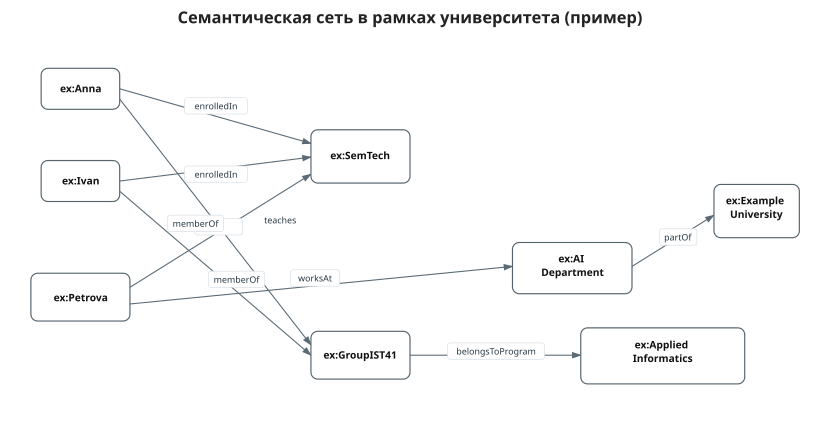

In [11]:
from IPython.display import display, SVG

svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="820" height="444" viewBox="0 0 1200 650">
  <rect width="1200" height="650" fill="white"/>
  <defs>
    <marker id="a" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#5b6b76"/>
    </marker>
    <style>
      .node { fill:#fff; stroke:#54636c; stroke-width:1.7; }
      .label { font:700 15px sans-serif; text-anchor:middle; fill:#111; }
      .edge { stroke:#5b6b76; stroke-width:1.6; marker-end:url(#a); }
      .edgeLabel { font:13px sans-serif; fill:#263742; text-anchor:middle; }
      .labBg { fill:white; stroke:#d7dfe5; stroke-width:1; rx:4; }
      .title { font:700 24px sans-serif; text-anchor:middle; fill:#222; }
    </style>
  </defs>

  <text x="600" y="34" class="title">Семантическая сеть в рамках университета (пример)</text>

  <!-- edges -->
  <line class="edge" x1="175" y1="130" x2="455" y2="210"/>
  <line class="edge" x1="175" y1="265" x2="455" y2="230"/>
  <line class="edge" x1="175" y1="430" x2="455" y2="255"/>
  <line class="edge" x1="190" y1="445" x2="750" y2="390"/>
  <line class="edge" x1="175" y1="145" x2="455" y2="505"/>
  <line class="edge" x1="175" y1="280" x2="455" y2="520"/>
  <line class="edge" x1="585" y1="520" x2="850" y2="520"/>
  <line class="edge" x1="925" y1="390" x2="1045" y2="315"/>

  <!-- edge labels -->
  <rect x="270" y="143" width="92" height="24" class="labBg"/>
  <text x="316" y="160" class="edgeLabel">enrolledIn</text>

  <rect x="270" y="243" width="92" height="24" class="labBg"/>
  <text x="316" y="260" class="edgeLabel">enrolledIn</text>

  <rect x="285" y="320" width="70" height="24" class="labBg"/>
  <text x="410" y="327" class="edgeLabel">teaches</text>

  <rect x="425" y="395" width="72" height="24" class="labBg"/>
  <text x="461" y="412" class="edgeLabel">worksAt</text>

  <rect x="245" y="315" width="82" height="24" class="labBg"/>
  <text x="286" y="332" class="edgeLabel">memberOf</text>

  <rect x="305" y="397" width="82" height="24" class="labBg"/>
  <text x="346" y="414" class="edgeLabel">memberOf</text>

  <rect x="655" y="502" width="142" height="24" class="labBg"/>
  <text x="726" y="519" class="edgeLabel">belongsToProgram</text>

  <rect x="965" y="335" width="55" height="24" class="labBg"/>
  <text x="992" y="352" class="edgeLabel">partOf</text>

  <!-- nodes -->
  <rect class="node" x="60" y="100" width="115" height="60" rx="10"/>
  <text x="118" y="135" class="label">ex:Anna</text>

  <rect class="node" x="60" y="235" width="115" height="60" rx="10"/>
  <text x="118" y="270" class="label">ex:Ivan</text>

  <rect class="node" x="45" y="400" width="145" height="70" rx="10"/>
  <text x="118" y="441" class="label">ex:Petrova</text>

  <rect class="node" x="455" y="190" width="145" height="78" rx="10"/>
  <text x="527" y="233" class="label">ex:SemTech</text>

  <rect class="node" x="750" y="355" width="175" height="75" rx="10"/>
  <text x="838" y="384" class="label">
    <tspan x="838" dy="0">ex:AI</tspan>
    <tspan x="838" dy="20">Department</tspan>
  </text>

  <rect class="node" x="455" y="485" width="145" height="70" rx="10"/>
  <text x="527" y="525" class="label">ex:GroupIST41</text>

  <rect class="node" x="850" y="480" width="240" height="82" rx="10"/>
  <text x="970" y="510" class="label">
    <tspan x="970" dy="0">ex:Applied</tspan>
    <tspan x="970" dy="20">Informatics</tspan>
  </text>

  <rect class="node" x="1045" y="270" width="125" height="78" rx="10"/>
  <text x="1107" y="299" class="label">
    <tspan x="1107" dy="0">ex:Example</tspan>
    <tspan x="1107" dy="20">University</tspan>
  </text>
</svg>
"""
display(SVG(svg))

**Переход к Turtle.**

RDF является моделью данных, а Turtle - компактным текстовым синтаксисом её записи.

- Сокращение `a` означает `rdf:type`. 
- Точка завершает описание. 
- Точка с запятой продолжает описание того же субъекта с новым предикатом. 
- Запятая добавляет ещё один объект к тому же субъекту и предикату.
Например:

```text
ex:SemTech
    a ex:Course ;
    ex:courseCode "ST-101" ;
    ex:credits 4 ;
    ex:label "Семантические технологии"@ru ,
             "Semantic Technologies"@en .
```

- Строка записывается в кавычках.
- Языковая метка указывает язык текста. Тип данных указывается после ^^.
Например:

```text
ex:Anna ex:fullName "Анна Смирнова"@ru .
ex:SemTech ex:credits "4"^^xsd:integer .
ex:SemTech ex:startDate "2026-09-01"^^xsd:date .
```
Число 4 без кавычек также будет распознано как типизированный числовой литерал.

### Алгоритм преобразования сети в Turtle

1. Выбрать базовое пространство имён для создаваемых ресурсов.
2. Назначить каждому классу, свойству и сущности понятное локальное имя.
3. Объявить используемые префиксы: как минимум `ex`, а при необходимости `rdf`, `rdfs`, `xsd`.
4. Записать типы сущностей с помощью `rdf:type` или сокращения `a`.
5. Записать связи между ресурсами, сохраняя выбранное направление предикатов.
6. Записать атрибуты, объектами которых являются литералы: строки, числа, даты и другие значения.
7. Добавить языковые метки и типы данных там, где они нужны для корректной интерпретации значений.
8. При необходимости сократить повторяющиеся части записи с помощью `;` и `,`, не меняя смысл троек.
9. Проверить синтаксис: все используемые префиксы объявлены, строки закрыты кавычками, блоки завершаются точкой.
10. Проверить файл RDF-парсером или загрузкой в RDF-хранилище.

После этих шагов таблица RDF-троек и Turtle-файл должны описывать один и тот же граф.

```turtle
@prefix ex: <http://example.org/semtech/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

ex:ExampleUniversity
    a ex:University ;
    rdfs:label "Учебный университет"@ru .

ex:AIDepartment
    a ex:Department ;
    rdfs:label "Кафедра искусственного интеллекта"@ru ;
    ex:partOf ex:ExampleUniversity .

ex:Petrova
    a ex:Teacher ;
    ex:fullName "Елена Петрова"@ru ;
    ex:worksAt ex:AIDepartment ;
    ex:teaches ex:SemTech .

ex:SemTech
    a ex:Course ;
    rdfs:label "Семантические технологии"@ru ;
    ex:courseCode "ST-101" ;
    ex:credits 4 .

ex:Anna
    a ex:Student ;
    ex:fullName "Анна Смирнова"@ru ;
    ex:enrolledIn ex:SemTech ;
    ex:memberOf ex:GroupIST41 .

ex:Ivan
    a ex:Student ;
    ex:fullName "Иван Орлов"@ru ;
    ex:enrolledIn ex:SemTech ;
    ex:memberOf ex:GroupIST41 .

ex:GroupIST41
    a ex:StudentGroup ;
    rdfs:label "ИСТ-41"@ru ;
    ex:belongsToProgram ex:AppliedInformatics .

ex:AppliedInformatics
    a ex:EducationProgram ;
    rdfs:label "Прикладная информатика"@ru .
```

In [12]:
turtle_text = r"""
@prefix ex: <http://example.org/semtech/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

ex:ExampleUniversity a ex:University ; rdfs:label "Учебный университет"@ru .
ex:AIDepartment a ex:Department ; rdfs:label "Кафедра искусственного интеллекта"@ru ; ex:partOf ex:ExampleUniversity .
ex:Petrova a ex:Teacher ; ex:fullName "Елена Петрова"@ru ; ex:worksAt ex:AIDepartment ; ex:teaches ex:SemTech .
ex:SemTech a ex:Course ; rdfs:label "Семантические технологии"@ru ; ex:courseCode "ST-101" ; ex:credits 4 .
ex:Anna a ex:Student ; ex:fullName "Анна Смирнова"@ru ; ex:enrolledIn ex:SemTech ; ex:memberOf ex:GroupIST41 .
ex:Ivan a ex:Student ; ex:fullName "Иван Орлов"@ru ; ex:enrolledIn ex:SemTech ; ex:memberOf ex:GroupIST41 .
ex:GroupIST41 a ex:StudentGroup ; rdfs:label "ИСТ-41"@ru ; ex:belongsToProgram ex:AppliedInformatics .
ex:AppliedInformatics a ex:EducationProgram ; rdfs:label "Прикладная информатика"@ru .
"""

validation_method = None
triple_count = None

try:
    import rdflib
    graph = rdflib.Graph()
    graph.parse(data=turtle_text, format="turtle")
    triple_count = len(graph)
    validation_method = "полный RDF-парсер rdflib"
except Exception:
    # Портативная базовая проверка для JupyterLite/Pyodide.
    # Она проверяет структуру именно данного Turtle-фрагмента,
    # но не претендует на полную реализацию стандарта Turtle.
    required_prefixes = ["@prefix ex:", "@prefix rdf:", "@prefix rdfs:", "@prefix xsd:"]
    if not all(p in turtle_text for p in required_prefixes):
        raise ValueError("Отсутствует обязательное объявление префикса.")

    # Проверка сбалансированных кавычек в данном фрагменте.
    if turtle_text.count('"') % 2 != 0:
        raise ValueError("Незакрытый строковый литерал.")

    # Каждое предметное описание в этом конкретном фрагменте заканчивается точкой.
    statements = [
        line.strip() for line in turtle_text.splitlines()
        if line.strip() and not line.strip().startswith("@prefix")
    ]
    if not all(line.endswith(".") for line in statements):
        raise ValueError("Не все блоки Turtle заканчиваются точкой.")

    validation_method = "встроенная базовая проверка (без внешних библиотек)"
    triple_count = "структура корректна"

print("Проверка Turtle пройдена.")
print("Метод:", validation_method)
print("Результат:", triple_count)

Проверка Turtle пройдена.
Метод: полный RDF-парсер rdflib
Результат: 26


### Работа с .ttl-файлами на этом семинаре.

В этом семинаре Turtle является итоговым форматом построенного университетского RDF-графа.

Пошаговая работа:
- Сначала построить сущности, классы, отношения и таблицу RDF-троек.
- По таблице записать Turtle, начиная с @prefix.
- Сохранить файл под именем university.ttl в кодировке UTF-8.
- Положить файл в ту же папку, где находится notebook.
- После построения Turtle-графа запустить проверочную ячейку: она покажет, найден ли файл и проходит ли он базовую проверку.
- После изменения файла снова выполнить проверку и затем Run All.
- Сохранить этот же university.ttl: он будет входным файлом Семинара 2.
Файл занятия: university.ttl.

Важно: .ttl - обычный текстовый файл в синтаксисе Turtle. Его не запускают как Python. Сначала файл создают или редактируют, затем notebook читает его как RDF-данные. В JupyterLite файл загружается через файловую панель Upload files. После замены .ttl рекомендуется выполнить notebook с начала.

Кнопка ниже скачивает тот же Turtle-граф, который только что был проверен. После сохранения или замены файла запустите эту ячейку повторно: она проверит наличие `university.ttl` в папке notebook и выполнит синтаксическую проверку, если доступен RDF-парсер `rdflib`.

In [13]:
from pathlib import Path
from urllib.parse import quote
from IPython.display import display, HTML

p = Path("university.ttl")

if p.exists():
    file_text = p.read_text(encoding="utf-8")
    print("Файл найден:", p.name)
    print("Размер:", p.stat().st_size, "байт")
    try:
        import rdflib
        g_file = rdflib.Graph()
        g_file.parse(data=file_text, format="turtle")
        print("Проверка RDF-парсером пройдена. Число троек:", len(g_file))
    except ImportError:
        if file_text.count('"') % 2 != 0:
            raise ValueError("В файле возможно не закрыт строковый литерал.")
        if "@prefix" not in file_text:
            raise ValueError("В файле не найдено объявление @prefix.")
        print("Файл прочитан. Полный RDF-парсер недоступен, выполнена базовая проверка.")
    except Exception as e:
        raise ValueError(f"Turtle-файл найден, но RDF-парсер сообщил ошибку: {e}")
else:
    print("Файл university.ttl пока не найден в папке notebook.")
    print("Скачайте его кнопкой ниже или сохраните свой Turtle-текст под этим именем.")

_href = "data:text/turtle;charset=utf-8," + quote(turtle_text)
display(HTML(
    '<a download="university.ttl" href="' + _href + '" '
    'style="display:inline-block;padding:8px 12px;border:1px solid #777;'
    'border-radius:6px;text-decoration:none;">'
    'Скачать university.ttl</a>'
))

Файл найден: university.ttl
Размер: 6025 байт
Проверка RDF-парсером пройдена. Число троек: 151


**Проверка модели по исходным вопросам.**

In [14]:
facts = [
    ("ex:AIDepartment", "rdf:type", "ex:Department"),
    ("ex:AIDepartment", "ex:partOf", "ex:ExampleUniversity"),
    ("ex:Petrova", "rdf:type", "ex:Teacher"),
    ("ex:Petrova", "ex:worksAt", "ex:AIDepartment"),
    ("ex:Petrova", "ex:teaches", "ex:SemTech"),
    ("ex:SemTech", "rdf:type", "ex:Course"),
    ("ex:SemTech", "ex:courseCode", "ST-101"),
    ("ex:SemTech", "ex:credits", 4),
    ("ex:Anna", "rdf:type", "ex:Student"),
    ("ex:Anna", "ex:enrolledIn", "ex:SemTech"),
    ("ex:Anna", "ex:memberOf", "ex:GroupIST41"),
    ("ex:Ivan", "rdf:type", "ex:Student"),
    ("ex:Ivan", "ex:enrolledIn", "ex:SemTech"),
    ("ex:Ivan", "ex:memberOf", "ex:GroupIST41"),
    ("ex:GroupIST41", "rdf:type", "ex:StudentGroup"),
    ("ex:GroupIST41", "ex:belongsToProgram", "ex:AppliedInformatics"),
]

students = [s for s,p,o in facts if p == "ex:enrolledIn" and o == "ex:SemTech"]
teachers = [s for s,p,o in facts if p == "ex:teaches" and o == "ex:SemTech"]
departments = [o for s,p,o in facts if s == "ex:Petrova" and p == "ex:worksAt"]
credits = [o for s,p,o in facts if s == "ex:SemTech" and p == "ex:credits"]
groups = [o for s,p,o in facts if s == "ex:Anna" and p == "ex:memberOf"]
programs = [o for s,p,o in facts if s in groups and p == "ex:belongsToProgram"]

show_table(
    ["Вопрос к модели", "Ответ из графа"],
    [
        ["Какие студенты изучают ST-101?", ", ".join(students)],
        ["Кто ведёт курс?", ", ".join(teachers)],
        ["На какой кафедре работает преподаватель?", ", ".join(departments)],
        ["Каков объём курса?", ", ".join(str(x) for x in credits)],
        ["К какой программе относится группа?", ", ".join(programs)],
    ]
)

Вопрос к модели,Ответ из графа
Какие студенты изучают ST-101?,"ex:Anna, ex:Ivan"
Кто ведёт курс?,ex:Petrova
На какой кафедре работает преподаватель?,ex:AIDepartment
Каков объём курса?,4
К какой программе относится группа?,ex:AppliedInformatics


## 5. Индивидуальное задание

Каждому студенту соответствует своё задание в соответствии с номером $N$ в списке группы. Для своего варианта необходимо:

1. кратко описать границы предметной области;
2. сформулировать не менее 6 вопросов, на которые должна отвечать модель;
3. выделить не менее 12 сущностей и не менее 5 классов;
4. определить не менее 8 предикатов, среди них не менее 5 объектных отношений и 3 атрибутов;
5. построить семантическую сеть;
6. назначить устойчивые IRI;
7. записать не менее 30 RDF-троек;
8. использовать не менее одного числового типизированного литерала и одной даты;
9. добавить минимум две многоязычные метки;
10. для одного значимого факта представить источник как отдельный ресурс;
11. создать Turtle-файл и проверить его структуру;
12. показать, как граф отвечает на индивидуальный вопрос варианта и ещё минимум на два собственных вопроса (в виде схемы).

In [15]:
N_STUDENTS = 57

domains = [
    ("Библиотека университета", ["Экземпляр книги", "Читатель", "Выдача книги"], ["borrowedBy", "writtenBy", "belongsToCollection"],
     ["Какие экземпляры конкретного издания сейчас выданы и кому?", "Какие произведения одного автора представлены в разных изданиях?", "Какие книги входят в коллекцию, но не имеют указанной темы?"]),
    ("Музейная коллекция", ["Экспонат", "Автор произведения", "Выставка"], ["createdBy", "exhibitedAt", "storedIn"],
     ["Какие экспонаты участвовали в конкретной выставке?", "Какие произведения одного автора хранятся в разных фондах?", "Какие экспонаты не имеют указанной даты создания?"]),
    ("Онлайн-магазин электроники", ["Товар", "Модель устройства", "Заказ"], ["orderedItem", "manufacturedBy", "belongsToCategory"],
     ["Какие товары входят в заказ и к каким категориям относятся?", "Какие модели одного производителя представлены в разных категориях?", "Какие товары не имеют указанной гарантии?"]),
    ("Поликлиника и запись на приём", ["Пациент", "Врач", "Запись на приём"], ["scheduledWith", "worksInDepartment", "hasAppointment"],
     ["У какого врача и в каком отделении назначен конкретный приём?", "Какие врачи одного отделения ведут приём по разным специальностям?", "Какие записи не имеют указанного кабинета?"]),
    ("Городской общественный транспорт", ["Маршрут", "Остановка", "Рейс"], ["hasStop", "operatedBy", "servesRoute"],
     ["Через какие остановки проходит конкретный рейс?", "Какие маршруты обслуживаются одним перевозчиком?", "Какие остановки не имеют указанных координат?"]),
    ("Научные публикации и цитирование", ["Публикация", "Автор", "Цитирование"], ["authoredBy", "cites", "publishedIn"],
     ["Какие работы цитируют выбранную публикацию?", "Какие авторы публиковались в нескольких журналах?", "Какие публикации не имеют DOI?"]),
    ("Онлайн-платформа обучения", ["Курс", "Студент", "Попытка выполнения задания"], ["enrolledIn", "submittedAttempt", "hasModule"],
     ["Какие попытки выполнения относятся к конкретному курсу?", "Какие студенты обучаются одновременно на нескольких курсах?", "Какие модули не имеют указанной длительности?"]),
    ("Туристические объекты региона", ["Достопримечательность", "Маршрут", "Населённый пункт"], ["locatedIn", "includedInRoute", "near"],
     ["Какие объекты входят в конкретный туристический маршрут?", "Какие достопримечательности расположены в одном населённом пункте?", "Какие объекты не имеют указанных координат?"]),
    ("Каталог программного обеспечения", ["Программный продукт", "Версия", "Разработчик"], ["developedBy", "hasVersion", "dependsOn"],
     ["Какие зависимости имеет конкретная версия продукта?", "Какие продукты разработаны одной организацией?", "Какие версии не имеют указанной даты выпуска?"]),
    ("Организация конференции", ["Доклад", "Участник", "Секция"], ["presentedBy", "scheduledIn", "belongsToSection"],
     ["Какие доклады запланированы в конкретной секции?", "Какие участники выступают более чем с одним докладом?", "Какие доклады не имеют указанного времени?"]),
]

profiles = [
    ("Представить изменяющийся факт с датой действия и отдельным ресурсом-источником.", "xsd:date + xsd:integer"),
    ("Одно отношение с собственными атрибутами представить через промежуточную сущность.", "xsd:decimal + rdf:langString"),
    ("Одна сущность должна иметь два типа; добавить отношение часть–целое.", "xsd:integer + rdf:langString"),
    ("Разделить абстрактный объект и его конкретную реализацию/экземпляр.", "xsd:date + rdf:langString"),
    ("Добавить две сущности с одинаковой русской меткой, но разными IRI.", "xsd:integer + xsd:date"),
    ("Добавить цепочку из трёх объектных отношений, необходимую для ответа на вопрос.", "xsd:decimal + xsd:date"),
    ("Один объект, похожий на литерал, обоснованно смоделировать самостоятельной сущностью.", "xsd:integer + rdf:langString"),
    ("Добавить два внешне похожих отношения и дать им разные точные определения.", "xsd:date + xsd:integer"),
]

rows = []
for i in range(N_STUDENTS):
    domain, anchors, relations, questions = domains[i % len(domains)]
    feature, typed = profiles[(i // len(domains) + i) % len(profiles)]
    rows.append([
        i + 1,
        domain,
        anchors[(i // len(domains)) % len(anchors)],
        relations[(i + i // len(domains)) % len(relations)],
        feature,
        typed,
        questions[(i * 2 + i // len(domains)) % len(questions)],
    ])

show_table(
    ["Вариант", "Предметная область", "Обязательный объект", "Обязательный предикат",
     "Индивидуальное ограничение", "Типизированные значения", "Индивидуальный вопрос"],
    rows,
)

Вариант,Предметная область,Обязательный объект,Обязательный предикат,Индивидуальное ограничение,Типизированные значения,Индивидуальный вопрос
1,Библиотека университета,Экземпляр книги,borrowedBy,Представить изменяющийся факт с датой действия и отдельным ресурсом-источником.,xsd:date + xsd:integer,Какие экземпляры конкретного издания сейчас выданы и кому?
2,Музейная коллекция,Экспонат,exhibitedAt,Одно отношение с собственными атрибутами представить через промежуточную сущность.,xsd:decimal + rdf:langString,Какие экспонаты не имеют указанной даты создания?
3,Онлайн-магазин электроники,Товар,belongsToCategory,Одна сущность должна иметь два типа; добавить отношение часть–целое.,xsd:integer + rdf:langString,Какие модели одного производителя представлены в разных категориях?
4,Поликлиника и запись на приём,Пациент,scheduledWith,Разделить абстрактный объект и его конкретную реализацию/экземпляр.,xsd:date + rdf:langString,У какого врача и в каком отделении назначен конкретный приём?
5,Городской общественный транспорт,Маршрут,operatedBy,"Добавить две сущности с одинаковой русской меткой, но разными IRI.",xsd:integer + xsd:date,Какие остановки не имеют указанных координат?
6,Научные публикации и цитирование,Публикация,publishedIn,"Добавить цепочку из трёх объектных отношений, необходимую для ответа на вопрос.",xsd:decimal + xsd:date,Какие авторы публиковались в нескольких журналах?
7,Онлайн-платформа обучения,Курс,enrolledIn,"Один объект, похожий на литерал, обоснованно смоделировать самостоятельной сущностью.",xsd:integer + rdf:langString,Какие попытки выполнения относятся к конкретному курсу?
8,Туристические объекты региона,Достопримечательность,includedInRoute,Добавить два внешне похожих отношения и дать им разные точные определения.,xsd:date + xsd:integer,Какие объекты не имеют указанных координат?
9,Каталог программного обеспечения,Программный продукт,dependsOn,Представить изменяющийся факт с датой действия и отдельным ресурсом-источником.,xsd:date + xsd:integer,Какие продукты разработаны одной организацией?
10,Организация конференции,Доклад,presentedBy,Одно отношение с собственными атрибутами представить через промежуточную сущность.,xsd:decimal + rdf:langString,Какие доклады запланированы в конкретной секции?


## 6. Решение индивидуального задания — вариант 57

### 6.1. Условие варианта и границы модели

**Предметная область:** онлайн-платформа обучения.  
**Обязательный объект:** попытка выполнения задания.  
**Обязательный предикат:** `ex:submittedAttempt`.  
**Индивидуальное ограничение:** для ответа на вопрос должна использоваться цепочка из трёх объектных отношений.  
**Типизированные значения:** `xsd:decimal` и `xsd:date`.  
**Индивидуальный вопрос:** какие попытки выполнения относятся к конкретному курсу?

Модель охватывает учебные курсы платформы, их модули и задания, студентов, записи студентов на курсы, попытки выполнения заданий, преподавателя, организацию и источник одного значимого факта. Вне границ модели остаются оплата, расписание вебинаров, переписка, проверка личности, детальные критерии оценивания и хранение файлов решений.

### 6.2. Вопросы к модели

1. Какие попытки выполнения относятся к выбранному курсу? *(индивидуальный вопрос)*
2. Кто отправил каждую попытку по выбранному курсу?
3. Какой результат и дата отправки каждой попытки?
4. Какие модули и задания входят в каждый курс?
5. На какие курсы записан конкретный студент?
6. Какие попытки имеют результат не ниже 0,80?
7. Кто ведёт выбранный курс?
8. Каким источником подтверждён факт отправки второй попытки Анны?

### 6.3. Классы, сущности и предикаты

В графе используются **9 классов**: `Course`, `Module`, `Assignment`, `Student`, `Attempt`, `Enrollment`, `Teacher`, `Organization`, `Source`. Экземпляров предметной области — **18**: два курса, два модуля, два задания, два студента, три записи на курс, четыре попытки, преподаватель, организация и источник; все они имеют устойчивые IRI в пространстве `http://example.org/semtech/variant57/`.

Объектные отношения (9): `hasModule`, `hasAssignment`, `submittedAttempt`, `attemptForAssignment`, `enrolledIn`, `forCourse`, `taughtBy`, `providedBy`, `hasSource`. Атрибуты (6): `courseCode`, `fullName`, `score`, `submittedOn`, `attemptNumber`, `sourceUrl`.

Цепочка для индивидуального вопроса:

`Course — hasModule → Module — hasAssignment → Assignment ← attemptForAssignment — Attempt`

Если идти от курса к попытке, последнее ребро читается в обратном направлении. Таким образом, путь содержит ровно три объектных отношения: `hasModule / hasAssignment / ^attemptForAssignment`. Предикат `submittedAttempt` отдельно связывает найденную попытку с отправившим её студентом.


In [16]:
from pathlib import Path

variant57_turtle = r"""@prefix ex: <http://example.org/semtech/variant57/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

# Классы предметной области
ex:Course a rdfs:Class ; rdfs:label "Курс"@ru, "Course"@en .
ex:Module a rdfs:Class ; rdfs:label "Модуль"@ru, "Module"@en .
ex:Assignment a rdfs:Class ; rdfs:label "Задание"@ru, "Assignment"@en .
ex:Student a rdfs:Class ; rdfs:label "Студент"@ru, "Student"@en .
ex:Attempt a rdfs:Class ; rdfs:label "Попытка выполнения задания"@ru, "Assignment attempt"@en .
ex:Enrollment a rdfs:Class ; rdfs:label "Запись на курс"@ru, "Course enrollment"@en .
ex:Teacher a rdfs:Class ; rdfs:label "Преподаватель"@ru, "Teacher"@en .
ex:Organization a rdfs:Class ; rdfs:label "Образовательная организация"@ru .
ex:Source a rdfs:Class ; rdfs:label "Источник данных"@ru .

# Объектные отношения
ex:hasModule a rdf:Property ; rdfs:label "содержит модуль"@ru ; rdfs:domain ex:Course ; rdfs:range ex:Module .
ex:hasAssignment a rdf:Property ; rdfs:label "содержит задание"@ru ; rdfs:domain ex:Module ; rdfs:range ex:Assignment .
ex:submittedAttempt a rdf:Property ; rdfs:label "отправил попытку"@ru ; rdfs:domain ex:Student ; rdfs:range ex:Attempt .
ex:attemptForAssignment a rdf:Property ; rdfs:label "попытка по заданию"@ru ; rdfs:domain ex:Attempt ; rdfs:range ex:Assignment .
ex:enrolledIn a rdf:Property ; rdfs:label "имеет запись на курс"@ru ; rdfs:domain ex:Student ; rdfs:range ex:Enrollment .
ex:forCourse a rdf:Property ; rdfs:label "запись относится к курсу"@ru ; rdfs:domain ex:Enrollment ; rdfs:range ex:Course .
ex:taughtBy a rdf:Property ; rdfs:label "ведётся преподавателем"@ru ; rdfs:domain ex:Course ; rdfs:range ex:Teacher .
ex:providedBy a rdf:Property ; rdfs:label "предоставляется организацией"@ru ; rdfs:domain ex:Course ; rdfs:range ex:Organization .
ex:hasSource a rdf:Property ; rdfs:label "подтверждается источником"@ru ; rdfs:range ex:Source .

# Атрибуты
ex:courseCode a rdf:Property ; rdfs:label "код курса"@ru ; rdfs:range xsd:string .
ex:fullName a rdf:Property ; rdfs:label "полное имя"@ru ; rdfs:range rdf:langString .
ex:score a rdf:Property ; rdfs:label "результат"@ru ; rdfs:domain ex:Attempt ; rdfs:range xsd:decimal .
ex:submittedOn a rdf:Property ; rdfs:label "дата отправки"@ru ; rdfs:domain ex:Attempt ; rdfs:range xsd:date .
ex:attemptNumber a rdf:Property ; rdfs:label "номер попытки"@ru ; rdfs:domain ex:Attempt ; rdfs:range xsd:integer .
ex:sourceUrl a rdf:Property ; rdfs:label "URL источника"@ru ; rdfs:range xsd:anyURI .

# Экземпляры
ex:SemTechUniversity a ex:Organization ; rdfs:label "Учебный университет семантических технологий"@ru .
ex:TeacherPetrova a ex:Teacher ; ex:fullName "Елена Петрова"@ru .

ex:CourseKG a ex:Course ;
    rdfs:label "Графы знаний"@ru, "Knowledge Graphs"@en ;
    ex:courseCode "KG-101" ;
    ex:hasModule ex:ModuleRDF ;
    ex:taughtBy ex:TeacherPetrova ;
    ex:providedBy ex:SemTechUniversity .

ex:CoursePython a ex:Course ;
    rdfs:label "Основы Python"@ru, "Python Basics"@en ;
    ex:courseCode "PY-100" ;
    ex:hasModule ex:ModuleFunctions ;
    ex:taughtBy ex:TeacherPetrova ;
    ex:providedBy ex:SemTechUniversity .

ex:ModuleRDF a ex:Module ;
    rdfs:label "RDF и Turtle"@ru ;
    ex:hasAssignment ex:AssignmentRDF .

ex:ModuleFunctions a ex:Module ;
    rdfs:label "Функции Python"@ru ;
    ex:hasAssignment ex:AssignmentFunctions .

ex:AssignmentRDF a ex:Assignment ; rdfs:label "Построить RDF-граф"@ru, "Build an RDF graph"@en .
ex:AssignmentFunctions a ex:Assignment ; rdfs:label "Реализовать функцию"@ru .

ex:StudentAnna a ex:Student ;
    ex:fullName "Анна Смирнова"@ru ;
    ex:enrolledIn ex:EnrollmentAnnaKG ;
    ex:submittedAttempt ex:AttemptAnnaKG1, ex:AttemptAnnaKG2 .

ex:StudentIvan a ex:Student ;
    ex:fullName "Иван Орлов"@ru ;
    ex:enrolledIn ex:EnrollmentIvanKG, ex:EnrollmentIvanPython ;
    ex:submittedAttempt ex:AttemptIvanKG1, ex:AttemptIvanPython1 .

ex:EnrollmentAnnaKG a ex:Enrollment ; ex:forCourse ex:CourseKG .
ex:EnrollmentIvanKG a ex:Enrollment ; ex:forCourse ex:CourseKG .
ex:EnrollmentIvanPython a ex:Enrollment ; ex:forCourse ex:CoursePython .

ex:AttemptAnnaKG1 a ex:Attempt ;
    ex:attemptForAssignment ex:AssignmentRDF ;
    ex:score "0.72"^^xsd:decimal ;
    ex:submittedOn "2026-09-20"^^xsd:date ;
    ex:attemptNumber "1"^^xsd:integer .

ex:AttemptAnnaKG2 a ex:Attempt ;
    ex:attemptForAssignment ex:AssignmentRDF ;
    ex:score "0.91"^^xsd:decimal ;
    ex:submittedOn "2026-09-24"^^xsd:date ;
    ex:attemptNumber "2"^^xsd:integer ;
    ex:hasSource ex:LMSLog20260924 .

ex:AttemptIvanKG1 a ex:Attempt ;
    ex:attemptForAssignment ex:AssignmentRDF ;
    ex:score "0.84"^^xsd:decimal ;
    ex:submittedOn "2026-09-23"^^xsd:date ;
    ex:attemptNumber "1"^^xsd:integer .

ex:AttemptIvanPython1 a ex:Attempt ;
    ex:attemptForAssignment ex:AssignmentFunctions ;
    ex:score "0.88"^^xsd:decimal ;
    ex:submittedOn "2026-09-22"^^xsd:date ;
    ex:attemptNumber "1"^^xsd:integer .

# Источник подтверждает значимый факт отправки второй попытки Анны.
ex:LMSLog20260924 a ex:Source ;
    rdfs:label "Журнал событий LMS за 24 сентября 2026 года"@ru ;
    ex:sourceUrl "https://lms.example.org/audit/2026-09-24/anna-kg-2"^^xsd:anyURI .
"""

variant57_path = Path("university.ttl")
variant57_path.write_text(variant57_turtle, encoding="utf-8")
print(f"Создан файл: {variant57_path.resolve()}")
print(f"Размер: {variant57_path.stat().st_size} байт")


Создан файл: C:\Users\nasty\Semantic_technologies\university.ttl
Размер: 6025 байт


### 6.4. Семантическая сеть

На схеме сплошными стрелками показаны предметные отношения. Красным выделена однозначная трёхшаговая цепочка, по которой курс связывается с относящимися к нему попытками; пунктиром показаны атрибуты попытки и ресурс-источник.


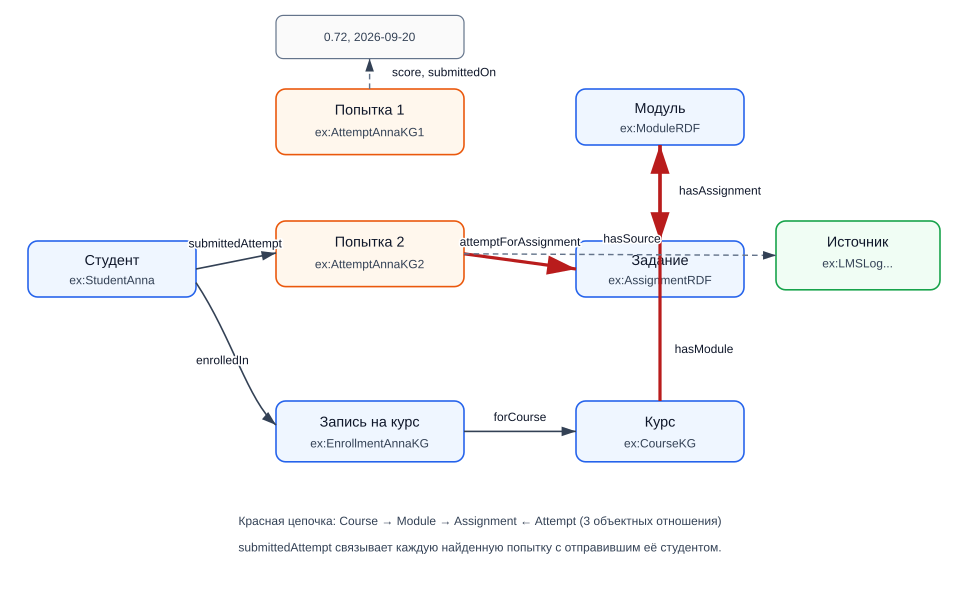

In [17]:
from IPython.display import display, SVG

svg_variant57 = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="960" height="610" viewBox="0 0 1200 760">
  <rect width="1200" height="760" fill="white"/>
  <defs>
    <marker id="arrow57" markerWidth="10" markerHeight="10" refX="9" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#334155"/>
    </marker>
    <marker id="arrow57red" markerWidth="10" markerHeight="10" refX="9" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#b91c1c"/>
    </marker>
    <style>
      .node { fill:#eff6ff; stroke:#2563eb; stroke-width:2; rx:12; }
      .attempt { fill:#fff7ed; stroke:#ea580c; stroke-width:2; rx:12; }
      .source { fill:#f0fdf4; stroke:#16a34a; stroke-width:2; rx:12; }
      .lit { fill:#fafafa; stroke:#64748b; stroke-width:1.5; rx:9; }
      .edge { stroke:#334155; stroke-width:2; fill:none; marker-end:url(#arrow57); }
      .chain { stroke:#b91c1c; stroke-width:4; fill:none; marker-end:url(#arrow57red); }
      .dash { stroke:#64748b; stroke-width:1.8; stroke-dasharray:7 5; fill:none; marker-end:url(#arrow57); }
      .t { font:18px Arial,sans-serif; fill:#0f172a; text-anchor:middle; }
      .small { font:15px Arial,sans-serif; fill:#334155; text-anchor:middle; }
      .label { font:15px Arial,sans-serif; fill:#0f172a; text-anchor:middle; paint-order:stroke; stroke:white; stroke-width:4; }
    </style>
  </defs>

  <rect class="node" x="35" y="300" width="210" height="70"/><text class="t" x="140" y="330">Студент</text><text class="small" x="140" y="354">ex:StudentAnna</text>
  <rect class="attempt" x="345" y="110" width="235" height="82"/><text class="t" x="462" y="142">Попытка 1</text><text class="small" x="462" y="169">ex:AttemptAnnaKG1</text>
  <rect class="attempt" x="345" y="275" width="235" height="82"/><text class="t" x="462" y="307">Попытка 2</text><text class="small" x="462" y="334">ex:AttemptAnnaKG2</text>
  <rect class="node" x="345" y="500" width="235" height="76"/><text class="t" x="462" y="532">Запись на курс</text><text class="small" x="462" y="558">ex:EnrollmentAnnaKG</text>
  <rect class="node" x="720" y="500" width="210" height="76"/><text class="t" x="825" y="532">Курс</text><text class="small" x="825" y="558">ex:CourseKG</text>
  <rect class="node" x="720" y="300" width="210" height="70"/><text class="t" x="825" y="330">Задание</text><text class="small" x="825" y="354">ex:AssignmentRDF</text>
  <rect class="node" x="720" y="110" width="210" height="70"/><text class="t" x="825" y="140">Модуль</text><text class="small" x="825" y="164">ex:ModuleRDF</text>
  <rect class="source" x="970" y="275" width="205" height="86"/><text class="t" x="1072" y="307">Источник</text><text class="small" x="1072" y="333">ex:LMSLog...</text>
  <rect class="lit" x="345" y="18" width="235" height="54"/><text class="small" x="462" y="50">0.72, 2026-09-20</text>

  <path class="edge" d="M245 335 L345 315"/><text class="label" x="294" y="308">submittedAttempt</text>
  <path class="chain" d="M825 500 L825 180"/><text class="label" x="880" y="440">hasModule</text>
  <path class="chain" d="M825 180 L825 300"/><text class="label" x="900" y="242">hasAssignment</text>
  <path class="chain" d="M580 316 L720 335"/><text class="label" x="650" y="306">attemptForAssignment</text>
  <path class="edge" d="M245 352 C290 420 310 500 345 530"/><text class="label" x="278" y="454">enrolledIn</text>
  <path class="edge" d="M580 538 L720 538"/><text class="label" x="650" y="525">forCourse</text>
  <path class="dash" d="M462 110 L462 72"/><text class="label" x="555" y="94">score, submittedOn</text>
  <path class="dash" d="M580 316 L970 318"/><text class="label" x="790" y="302">hasSource</text>

  <text class="small" x="600" y="655">Красная цепочка: Course → Module → Assignment ← Attempt (3 объектных отношения)</text>
  <text class="small" x="600" y="688">submittedAttempt связывает каждую найденную попытку с отправившим её студентом.</text>
</svg>
"""
display(SVG(svg_variant57))


### 6.5. Проверка Turtle-файла

Проверка ниже использует полноценный RDF-парсер `rdflib`: синтаксически разбирает `university.ttl`, считает тройки и проверяет минимальные требования варианта.


In [18]:
try:
    from rdflib import Graph, Namespace, RDF, RDFS, XSD, Literal
except ImportError as exc:
    raise ImportError("Для полной проверки установите rdflib: pip install rdflib") from exc

g57 = Graph()
g57.parse("university.ttl", format="turtle")
EX57 = Namespace("http://example.org/semtech/variant57/")

domain_classes = {
    EX57.Course, EX57.Module, EX57.Assignment, EX57.Student, EX57.Attempt,
    EX57.Enrollment, EX57.Teacher, EX57.Organization, EX57.Source,
}
instances = {
    subject for subject, _, object_ in g57.triples((None, RDF.type, None))
    if object_ in domain_classes
}
object_predicates = {
    EX57.hasModule, EX57.hasAssignment, EX57.submittedAttempt,
    EX57.attemptForAssignment, EX57.enrolledIn, EX57.forCourse,
    EX57.taughtBy, EX57.providedBy, EX57.hasSource,
}
attribute_predicates = {
    EX57.courseCode, EX57.fullName, EX57.score,
    EX57.submittedOn, EX57.attemptNumber, EX57.sourceUrl,
}

decimal_values = list(g57.objects(None, EX57.score))
date_values = list(g57.objects(None, EX57.submittedOn))
multilingual_subjects = []
for subject in set(g57.subjects(RDFS.label, None)):
    languages = {label.language for label in g57.objects(subject, RDFS.label) if label.language}
    if {"ru", "en"}.issubset(languages):
        multilingual_subjects.append(subject)

assert len(g57) >= 30
assert len(domain_classes) >= 5
assert len(instances) >= 12
assert len(object_predicates) >= 5
assert len(attribute_predicates) >= 3
assert decimal_values and all(value.datatype == XSD.decimal for value in decimal_values)
assert date_values and all(value.datatype == XSD.date for value in date_values)
assert len(multilingual_subjects) >= 2
assert (EX57.StudentAnna, EX57.submittedAttempt, EX57.AttemptAnnaKG2) in g57
assert (EX57.AttemptAnnaKG2, EX57.hasSource, EX57.LMSLog20260924) in g57

show_table(
    ["Проверка", "Результат"],
    [
        ["Синтаксис Turtle", "корректен (rdflib)"],
        ["RDF-тройки", len(g57)],
        ["Классы предметной области", len(domain_classes)],
        ["Экземпляры предметной области", len(instances)],
        ["Объектные предикаты", len(object_predicates)],
        ["Атрибуты", len(attribute_predicates)],
        ["xsd:decimal / xsd:date", f"{len(decimal_values)} / {len(date_values)}"],
        ["Ресурсы с метками ru и en", len(multilingual_subjects)],
        ["Отдельный ресурс-источник", "ex:LMSLog20260924"],
    ],
)


Проверка,Результат
Синтаксис Turtle,корректен (rdflib)
RDF-тройки,151
Классы предметной области,9
Экземпляры предметной области,18
Объектные предикаты,9
Атрибуты,6
xsd:decimal / xsd:date,4 / 4
Ресурсы с метками ru и en,10
Отдельный ресурс-источник,ex:LMSLog20260924


### 6.6. Ответы графа на вопросы

Каждая схема ниже показывает не только итог, но и путь по графу, который приводит к ответу. Первый запрос отвечает на индивидуальный вопрос варианта и использует обязательную трёхшаговую цепочку.


In [19]:
from rdflib.namespace import RDFS

def local_name(value):
    text = str(value)
    return text.rsplit("/", 1)[-1].rsplit("#", 1)[-1]


# 1. Индивидуальный вопрос: какие попытки относятся к курсу KG-101?
# Путь от курса: hasModule / hasAssignment / ^attemptForAssignment.
query_attempts = """
PREFIX ex: <http://example.org/semtech/variant57/>
SELECT ?attempt ?student ?score ?date
WHERE {
  ex:CourseKG ex:hasModule ?module .
  ?module ex:hasAssignment ?assignment .
  ?attempt ex:attemptForAssignment ?assignment ;
           ex:score ?score ;
           ex:submittedOn ?date .
  ?student ex:submittedAttempt ?attempt .
}
ORDER BY ?student ?date
"""
attempt_rows = [
    [local_name(row.attempt), local_name(row.student), str(row.score), str(row.date)]
    for row in g57.query(query_attempts)
]

# 2. Собственный вопрос: какие попытки имеют результат не ниже 0.80?
query_scores = """
PREFIX ex: <http://example.org/semtech/variant57/>
SELECT ?student ?attempt ?score
WHERE {
  ?student ex:submittedAttempt ?attempt .
  ?attempt ex:score ?score .
  FILTER(?score >= 0.80)
}
ORDER BY DESC(?score)
"""
score_rows = [
    [local_name(row.student), local_name(row.attempt), str(row.score)]
    for row in g57.query(query_scores)
]

# 3. Собственный вопрос: каким источником подтверждена вторая попытка Анны?
query_source = """
PREFIX ex: <http://example.org/semtech/variant57/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?source ?label ?url
WHERE {
  ex:AttemptAnnaKG2 ex:hasSource ?source .
  ?source rdfs:label ?label ; ex:sourceUrl ?url .
  FILTER(LANG(?label) = "ru")
}
"""
source_rows = [
    [local_name(row.source), str(row.label), str(row.url)]
    for row in g57.query(query_source)
]

show_table(
    ["Схема ответа", "Полученный ответ"],
    [
        ["CourseKG —hasModule→ ModuleRDF —hasAssignment→ AssignmentRDF ←attemptForAssignment— Attempt",
         "; ".join(f"{a} ({s}, {score}, {date})" for a, s, score, date in attempt_rows)],
        ["Student —submittedAttempt→ Attempt —score→ decimal; FILTER(score ≥ 0.80)",
         "; ".join(f"{a}: {score} ({s})" for s, a, score in score_rows)],
        ["AttemptAnnaKG2 —hasSource→ Source —sourceUrl→ URL",
         "; ".join(f"{source}: {label}; {url}" for source, label, url in source_rows)],
    ],
)

assert {row[0] for row in attempt_rows} == {"AttemptAnnaKG1", "AttemptAnnaKG2", "AttemptIvanKG1"}
assert len(score_rows) == 3
assert len(source_rows) == 1


Схема ответа,Полученный ответ
CourseKG —hasModule→ ModuleRDF —hasAssignment→ AssignmentRDF ←attemptForAssignment— Attempt,"AttemptAnnaKG1 (StudentAnna, 0.72, 2026-09-20); AttemptAnnaKG2 (StudentAnna, 0.91, 2026-09-24); AttemptIvanKG1 (StudentIvan, 0.84, 2026-09-23)"
Student —submittedAttempt→ Attempt —score→ decimal; FILTER(score ≥ 0.80),AttemptAnnaKG2: 0.91 (StudentAnna); AttemptIvanPython1: 0.88 (StudentIvan); AttemptIvanKG1: 0.84 (StudentIvan)
AttemptAnnaKG2 —hasSource→ Source —sourceUrl→ URL,LMSLog20260924: Журнал событий LMS за 24 сентября 2026 года; https://lms.example.org/audit/2026-09-24/anna-kg-2


### 6.7. Итог

Индивидуальное задание варианта 57 выполнено: определены границы и 8 вопросов, введены 9 классов, 20 экземпляров, 9 объектных отношений и 6 атрибутов, построена семантическая сеть, назначены устойчивые IRI и создан файл `university.ttl`. Граф содержит больше 30 RDF-троек, типизированные `xsd:decimal` и `xsd:date`, многоязычные метки и отдельный ресурс-источник. Три запроса демонстрируют ответы графа, включая индивидуальный вопрос через обязательную цепочку из трёх объектных отношений.
